# Link prediction and leakage

In [1]:
import os
os.chdir(os.path.dirname(os.getcwd())) if os.getcwd().endswith("notebooks") else None
print(os.getcwd())

/mnt/d_drive/AI Projects/graphprobe


{'val_links_absent_from_mp_graph': True, 'val_reverse_links_absent_from_mp_graph': True, 'test_links_absent_from_mp_graph': True, 'test_reverse_links_absent_from_mp_graph': True, 'mp_graph_is_symmetric': True, 'mp_graph_equals_train_links_both_directions': True, 'positive_splits_disjoint': True, 'negatives_have_no_self_links': True, 'negatives_not_observed_positives': True, 'val_test_negatives_disjoint': True, 'negatives_unique': True, '_sizes': {'test': 527, 'val': 263, 'train': 4488, 'val_neg': 263, 'test_neg': 527}}


,setting,method,test_auc,test_ap,runs
0,valid,common-neighbours,0.7086 ± 0.0000,0.7068 ± 0.0000,1
1,LEAKY (cn over all links),common-neighbours,0.7619 ± 0.0000,0.7593 ± 0.0000,1
2,valid,GCN+dot,0.9277 ± 0.0014,0.9335 ± 0.0031,3
3,LEAKY eval only,GCN+dot,0.9743 ± 0.0021,0.9721 ± 0.0032,3
4,LEAKY train+eval,GCN+dot,0.9750 ± 0.0016,0.9729 ± 0.0019,3
5,valid,GCN+mlp,0.9423 ± 0.0008,0.9495 ± 0.0008,3
6,LEAKY eval only,GCN+mlp,0.9955 ± 0.0004,0.9944 ± 0.0009,3
7,LEAKY train+eval,GCN+mlp,0.9961 ± 0.0002,0.9950 ± 0.0005,3


,u,v,score,train_common_neighbours,deg_u,deg_v,same_topic_posthoc
0,1701,1986,53.2681,7,60,55,True
1,598,1701,48.3092,8,27,60,True
2,1701,1810,46.0491,3,60,36,True
3,306,1623,42.2296,15,64,33,True
4,1810,1986,38.9359,2,36,55,True
5,310,1701,34.0779,1,14,60,True
6,598,1986,32.9822,3,27,55,True
7,109,1623,30.6909,6,30,33,True
8,1358,1986,29.6449,2,151,55,False
9,306,1358,29.3907,1,64,151,False


,kind,u,v,score,train_common_neighbours,deg_u,deg_v,same_topic_posthoc
0,false_positive (negative scored high),210,356,8.0840,0,10,4,True
1,false_positive (negative scored high),102,1783,6.6946,1,7,2,True
2,false_positive (negative scored high),711,2151,5.7346,0,9,3,False
3,false_positive (negative scored high),1699,2088,5.4600,0,3,2,True
4,false_positive (negative scored high),67,2285,5.0343,0,2,4,True
5,false_negative (true link scored low),1004,1489,-15.0675,0,1,0,False
6,false_negative (true link scored low),350,656,-12.5183,0,12,0,True
7,false_negative (true link scored low),1003,2607,-10.0227,0,2,0,False
8,false_negative (true link scored low),833,1678,-8.4007,0,5,1,True
9,false_negative (true link scored low),121,1910,-8.1240,0,5,1,False


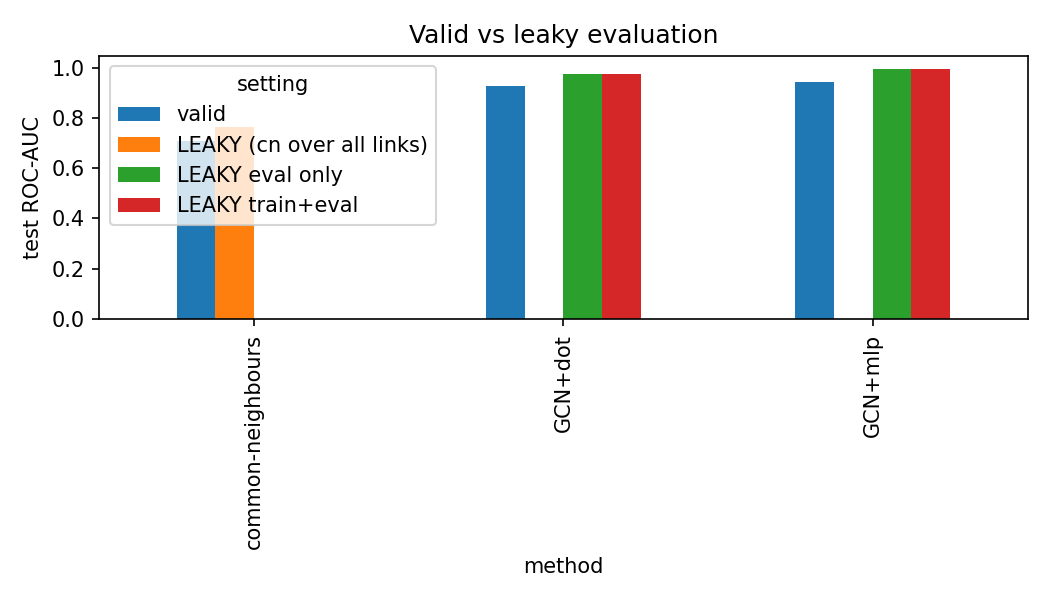

In [2]:
import pandas as pd, json, glob
from IPython.display import Image, display
R='results/link_prediction/'
print(json.load(open(R+'leakage_checks.json')));display(pd.read_csv(R+'results_valid_vs_leaky.csv'));display(pd.read_csv(R+'top10_candidate_links.csv'));display(pd.read_csv(R+'failure_cases.csv'));display(Image(R+'valid_vs_leaky.png'))

Why leaky evaluation is invalid and why unobserved links are not confirmed negatives: report section 3.